In [1]:
import os
if os.getenv("CUDA_VISIBLE_DEVICES") is None:
    gpu_num = 0 # Use "" to use the CPU
    os.environ["CUDA_VISIBLE_DEVICES"] = f"{gpu_num}"
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'

# Configure the notebook to use only a single GPU and allocate only as much memory as needed
# For more details, see https://www.tensorflow.org/guide/gpu
import tensorflow as tf
from tensorflow.keras import Model,Layer
from tensorflow.keras.layers import Dense
gpus = tf.config.list_physical_devices('GPU')

if gpus:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
    except RuntimeError as e:
        print(e)
# Avoid warnings from TensorFlow
tf.get_logger().setLevel('ERROR')


import matplotlib.pyplot as plt
import numpy as np
import h5py
import math
import sionna

# Load the required Sionna components
from sionna.phy import Block
from sionna.phy.mapping import Constellation, Mapper, Demapper, BinarySource
from sionna.phy.fec.ldpc import LDPC5GEncoder, LDPC5GDecoder, LDPCBPDecoder, EXITCallback
from sionna.phy.fec.interleaving import RandomInterleaver, Deinterleaver
from sionna.phy.fec.scrambling import Scrambler, Descrambler
from sionna.phy.fec.utils import GaussianPriorSource, load_parity_check_examples, \
                                 get_exit_analytic, plot_exit_chart, plot_trajectory
from sionna.phy.utils import ebnodb2no, hard_decisions, PlotBER, split_dim, expand_to_rank
from sionna.phy.channel import AWGN
from scipy.sparse import csr_matrix

sionna.phy.config.seed = 42 # Set seed for reproducible random number generation
import sionna as sn
from custom_classes_shaping import Demapper_optimized
from pn_classes import PhaseNoise, PN_Compensation, PTRS_Adder

import ccdm
from ccdm_initialize import initialize

from end_to_end_model import symbol_points_qam64

E0000 00:00:1789154060.421849   24108 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1789154060.425879   24108 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1789154060.435571   24108 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1789154060.435589   24108 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1789154060.435591   24108 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1789154060.435592   24108 computation_placer.cc:177] computation placer already registered. Please check linka

In [3]:
spiral64 = np.array([-3.23430101168031 - 1.56076569839251j,
2.15695827489919 - 4.67102388416793j,
2.81935751977957 + 6.91406029641468j,
6.35137835624533 + 0.638744044219888j,
1.32477370638642 - 11.0358151515758j,
-6.84562358822951 - 7.64983471576675j,
-4.79175587108559 + 6.96777479992746j,
-9.37520170186632 + 0.389275737097664j,
9.67023796527796 - 7.00290580787480j,
12.5422086181764 + 2.26449228254309j,
-2.52053104552802 + 14.0905132408553j,
7.66188851957678 + 11.1581269003104j,
1.31523615371292 - 17.3047082990499j,
-10.3914364445761 - 12.9483725966099j,
-12.2386152647051 + 8.81666892832029j,
-15.6953664920567 - 2.17915387422084j,
11.2241612925136 - 21.2674195222366j,
23.3535788596083 - 8.31766583944096j,
10.8241893010955 + 23.9462528549827j,
23.5025442647073 + 9.98168982660931j,
-15.9724959620627 - 24.5252370621897j,
-27.6697392261302 - 6.90782728379627j,
-8.52848887884541 + 25.6436016693895j,
-24.3303668585728 + 13.3893796573552j,
13.2930388149352 - 12.2893133575096j,
18.8495876652243 + 0.000598534504740977j,
1.69196191450234 + 20.2665555412421j,
14.4112128168745 + 13.2755475704559j,
-5.91974679520062 - 22.5407460204956j,
-18.9721069096630 - 12.2128052531286j,
-12.9076909694987 + 16.6652692772391j,
-21.5071641941432 + 3.68914045518164j,
-16.0415670171265 - 45.6182360085846j,
20.8306682285244 - 44.4981657044597j,
46.2571959895967 + 20.7221770264619j,
46.7752628523418 - 17.4070389796295j,
-49.6367751657554 - 20.7599440036023j,
-49.1617607711529 + 19.8637517805426j,
18.6819561872872 + 47.9542380862089j,
-20.6966039476363 + 47.9692073131739j,
-9.74357392513642 - 41.0375323056766j,
21.9354423664886 - 36.9232857846418j,
38.9056005377088 + 21.5776899014975j,
42.1957700548896 - 11.4346409442105j,
-42.6890030910252 - 21.0150754131216j,
-44.4754373988375 + 14.5885114824764j,
13.0514215123313 + 43.3379777322169j,
-21.2672416730713 + 40.8261274970473j,
5.16091239559964 - 29.5709365665655j,
24.5549899229055 - 18.5416807301648j,
21.0731519183703 + 24.4461995352028j,
31.3457175412846 + 3.32543757760490j,
-25.9616204762402 - 23.9212903445595j,
-34.5401954693062 + 0.482161704316180j,
-1.43480050232820 + 32.9989976944148j,
-24.2260953379511 + 23.5501224010518j,
-2.40107452596603 - 35.9816603155733j,
23.5569452284180 - 28.3013316466114j,
30.5665353863504 + 23.1562746925090j,
37.3374206595994 - 4.30169779089051j,
-34.8750719217673 - 22.3278310064816j,
-39.8508365287125 + 7.98500417485104j,
6.16747056520371 + 38.6222251831795j,
-22.7403083402242 + 32.7571747868810j])

In [2]:
def normalize_constellation(points, probabilities):

    # Compute the power of the constellation
    power = np.sum(probabilities * np.abs(points)**2)
    # Normalize the constellation points
    normalized_points = points / np.sqrt(power)
    return normalized_points


def generate_ldpc_H_matrix(n_ldpc: int, rate: float, q: int, file_path: str) -> np.ndarray:
    # Compute derived parameters
    k_ldpc = int(n_ldpc * rate)
    N_p = n_ldpc - k_ldpc  # number of parity bits

    data = []
    with open(file_path, "r") as file:
        for line in file:
            values = [int(v) for v in line.strip().split()]
            data.append(values)

    H_matrix = np.zeros((N_p, n_ldpc), dtype=np.uint8)

    for index, base_addresses in enumerate(data):
        base_addresses = np.array(base_addresses)

        for addr in base_addresses:
            H_matrix[addr, 360 * index + 0] = 1

        for m in range(1, 360):
            for addr in base_addresses:
                new_addr = (addr + (m % 360) * q) % N_p
                H_matrix[new_addr, 360 * index + m] = 1

    P_matrix = np.zeros((N_p, N_p), dtype=int)
    np.fill_diagonal(P_matrix, 1)
    for i in range(1, N_p):
        P_matrix[i, i - 1] = 1

    H_matrix[:, k_ldpc:] = P_matrix

    return H_matrix

In [3]:
class BICM_scheme(Model):

    def __init__(self, batch_size, num_bp_iter, use_dvb, symbol_points, perfect_csi, use_upsampling_filtering_pn, pn_freq, condition):
        super().__init__() # Must call the Keras model initializer

        self.use_dvb = use_dvb
        self.batch_size = batch_size
        llr_max_value = 120.00

        self.channel = AWGN()
        self.num_bits_per_symbol = 6

        if self.use_dvb:

            r = 3/5
            n_ldpc = 16200
            self.n = n_ldpc
            self.k = int(n_ldpc*r)

            parity_matrix = generate_ldpc_H_matrix(n_ldpc=n_ldpc,rate=r,q=21,file_path="ldpccode_short_3_5.txt")
            H_csr = csr_matrix(parity_matrix[:, :self.k])
            self.H_sparse = tf.sparse.SparseTensor(
                indices=np.vstack((H_csr.nonzero()[0], H_csr.nonzero()[1])).T.astype(np.int64),
                values=H_csr.data.astype(np.int32),
                dense_shape=H_csr.shape
            )
            self.H_sparse_test = csr_matrix(parity_matrix[:, :self.k])

            self.decoder = LDPCBPDecoder(parity_matrix, # connect encoder (for shared code parameters)
                                    cn_update="boxplus-phi", # use the exact boxplus function
                                    num_iter=num_bp_iter,
                                    llr_max=llr_max_value,
                                   hard_out=False)
            self.source = BinarySource()

        else:
            self.k = 864
            self.n = 1440

            self.binary_source = BinarySource()
            self.encoder = LDPC5GEncoder(self.k, self.n)
            # self.siso_decoder = LDPC5GDecoder(self.encoder, return_infobits=False, num_iter=num_bp_iter, hard_out=False, llr_max=llr_max_value, return_state=True)
            self.decoder = LDPC5GDecoder(self.encoder, return_infobits=True, hard_out=True, num_iter=num_bp_iter, llr_max=llr_max_value, return_state=False)

        # initialize a random interleaver and corresponding deinterleaver
        self.interleaver = RandomInterleaver()
        self.deinterleaver = Deinterleaver(self.interleaver)

        probabilities = np.ones_like(symbol_points)/(2**self.num_bits_per_symbol)

        power = np.sum(probabilities * np.abs(symbol_points)**2)
        self.normalized_points = symbol_points / np.sqrt(power)

        constellation = Constellation("custom", num_bits_per_symbol=self.num_bits_per_symbol , points = self.normalized_points)

        # mapper and demapper
        self.mapper = Mapper(constellation=constellation)

        if pn_freq == '220':
            fc = 220e9
            pn_var = 0.0108
        elif pn_freq == '120':
            fc = 120e9
            pn_var = 0.0032
        # self.demapper = Demapper("app", constellation=constellation) # APP demapper
        self.demapper = Demapper_optimized("app", constellation=constellation, pn_var=pn_var, condition=condition) # APP demapper

        self.num_symbols = int(self.n/self.num_bits_per_symbol)
        self.use_upsampling_filtering_pn  = use_upsampling_filtering_pn

        if use_upsampling_filtering_pn:
            self.upsampler = sn.phy.signal.Upsampling(samples_per_symbol=4)
            self.tx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                             samples_per_symbol=4,
                                                             span_in_symbols=32)
            self.rx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                             samples_per_symbol=4,
                                                             span_in_symbols=32)

            num_ptrs_blocks = 32
            symbols_per_ptrs_block = 4
            block_size_ptrs = self.num_symbols+ 4*32
            bandwidth = 960e3*4096

            samples = 4*(block_size_ptrs+32)

            self.downsampler = sn.phy.signal.Downsampling(samples_per_symbol=4,
                                                          offset = self.rx_filter.length - 1,
                                                     num_symbols=tf.cast(block_size_ptrs, tf.int32))

            path_to_mat = "../PreloadedMats/ptrs_CAZAC_4_32.mat"

            self.ptrs_adder = PTRS_Adder(path_to_mat, num_ptrs_blocks, symbols_per_ptrs_block, block_size_ptrs, batch_size)
            self.pn_compensate = PN_Compensation(self.ptrs_adder.ptrs_indices, self.ptrs_adder.data_indices, block_size_ptrs\
                                                 , self.ptrs_adder.pilots,batch_size, num_ptrs_blocks, symbols_per_ptrs_block)
            self.pn_tx = PhaseNoise(model_type='13', bandwidth=bandwidth, fc=fc, n_samples=samples)
            self.pn_rx = PhaseNoise(model_type='11', bandwidth=bandwidth, fc=fc, n_samples=samples)


    @tf.function # Graph execution to speed things up
    def __call__(self, batch_size, ebno_db):
        no = ebnodb2no(ebno_db,
           num_bits_per_symbol=self.num_bits_per_symbol,
           coderate=3/5)

        if self.use_dvb:
            # u, c = next(self.iterator)
            b_stream = tf.cast(self.source([batch_size, self.k]),tf.int32) # generate random data
            p_bits = tf.transpose(tf.sparse.sparse_dense_matmul(self.H_sparse, tf.transpose(b_stream)))
            p_bits = tf.math.mod(p_bits, 2)
            p_bits = tf.math.mod(tf.math.cumsum(p_bits, axis=1), 2)
            c = tf.concat([b_stream, p_bits], axis=1)
        else:
            u = self.binary_source([self.batch_size, self.k])
            c = tf.cast(self.encoder(u),tf.uint8)

        # u, c = next(self.iterator)
        c_int = self.interleaver(c)
        x = self.mapper(c_int)

        if self.use_upsampling_filtering_pn:
            ptrs_x_mod = self.ptrs_adder(x)
            x_up = self.upsampler(ptrs_x_mod)
            x_tx_filt = self.tx_filter(x_up)
            pn_out, _, _ = self.pn_tx(x_tx_filt)
            y_channel = self.channel(pn_out, no)
            y_channel_pn, _, _ = self.pn_rx(y_channel)
            y_rx_filt = self.rx_filter(y_channel_pn)
            y = self.downsampler(y_rx_filt)
            # print('y.shape: ',y.shape)
            _, y_data_vec = self.pn_compensate(y)
        else:
            y_data_vec = self.channel(x, no)
        ##################################
        # llr_ch = self.demapper(y_data_vec, no) # demapp
        llr_ch = self.demapper(y_data_vec, no, self.normalized_points)
        llr_deint = self.deinterleaver(llr_ch)

        if self.use_dvb:
            llr_u_stream = self.decoder(llr_deint)
            u_stream_hat = tf.cast(tf.greater_equal(0.0, -llr_u_stream), tf.int32)
            b_stream_hat = u_stream_hat[:,:self.k]
            return b_stream, b_stream_hat
        else:
            b_stream_hat = self.decoder(llr_deint) # run LDPC decoder
            return u, b_stream_hat


In [13]:
import time

start_time = time.perf_counter()

In [14]:
RESULTS_DIR = "results_gcs_benchmark"

snr_list = [13]
papr_list = [5.5, 6.0, 6.5, 7.0]

batch_size = 20
num_bp_iter = 40
use_dvb = True
perfect_csi = False
use_upsampling_filtering_pn = True
pn_freq = '120' # 220
condition = 'lowpn' # awgn highsnr

ber_plot_bicm = PlotBER("ber_plot_bicm")



for snr_db in snr_list:
    for papr_db in papr_list:
        exp_name = f"snr_{snr_db}_papr_{papr_db}"
        plotname = f"papr_{papr_db}"
        data = np.load(f"../Experiments_April/{RESULTS_DIR}/{exp_name}.npz")
        points = data["constellation_points"]

        model_bicm = BICM_scheme(batch_size, num_bp_iter, use_dvb, points, perfect_csi, use_upsampling_filtering_pn, pn_freq, condition)

        ber_plot_bicm.simulate(model_bicm, # the function have defined previously
                                  ebno_dbs=np.arange(6.6, 12.0, 0.1), # sim SNR range
                                  legend=plotname,
                                  add_bler = True,
                                  add_ber = True,
                                  max_mc_iter=250,
                                  num_target_block_errors=100,
                                  batch_size=batch_size,
                                  soft_estimates=False,
                                  early_stop=True,
                                  show_fig=False,
                                  forward_keyboard_interrupt=False)

data = np.load(f"../Experiments_April/no_constraint_gcs.npz")
points = data["constellation_points"]

model_bicm = BICM_scheme(batch_size, num_bp_iter, use_dvb, points, perfect_csi, use_upsampling_filtering_pn, pn_freq, condition)
plotname = "No PAPR"
ber_plot_bicm.simulate(model_bicm, # the function have defined previously
                          ebno_dbs=np.arange(6.6, 12.0, 0.1), # sim SNR range
                          legend=plotname,
                          add_bler = True,
                          add_ber = True,
                          max_mc_iter=250,
                          num_target_block_errors=100,
                          batch_size=batch_size,
                          soft_estimates=False,
                          early_stop=True,
                          show_fig=False,
                          forward_keyboard_interrupt=False)


points = symbol_points_qam64

model_bicm = BICM_scheme(batch_size, num_bp_iter, use_dvb, points, perfect_csi, use_upsampling_filtering_pn, pn_freq, condition)
plotname = "64-QAM"
ber_plot_bicm.simulate(model_bicm, # the function have defined previously
                          ebno_dbs=np.arange(6.6, 12.0, 0.1), # sim SNR range
                          legend=plotname,
                          add_bler = True,
                          add_ber = True,
                          max_mc_iter=250,
                          num_target_block_errors=100,
                          batch_size=batch_size,
                          soft_estimates=False,
                          early_stop=True,
                          show_fig=False,
                          forward_keyboard_interrupt=False)

bicm_ber = ber_plot_bicm.ber
bicm_snr = ber_plot_bicm.snr


end_time = time.perf_counter()

elapsed_time = end_time - start_time
print(f"Execution time: {elapsed_time:.6f} seconds")



I0000 00:00:1788017728.051233   97960 cuda_dnn.cc:529] Loaded cuDNN version 91400


EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      6.6 | 1.4824e-01 | 1.0000e+00 |      144089 |      972000 |          100 |         100 |         5.2 |reached target block errors
      6.7 | 1.4641e-01 | 1.0000e+00 |      142307 |      972000 |          100 |         100 |         0.7 |reached target block errors
      6.8 | 1.4389e-01 | 1.0000e+00 |      139857 |      972000 |          100 |         100 |         0.8 |reached target block errors
      6.9 | 1.4337e-01 | 1.0000e+00 |      139357 |      972000 |          100 |         100 |         0.7 |reached target block errors
      7.0 | 1.3968e-01 | 1.0000e+00 |      135770 |      972000 |          100 |         100 |         0.7 |reached target block errors
      7.1 | 1.3758e-01 | 1.0000e+00 |      133725 |      972000 |

## Added for 220GHz benchmark

In [5]:
batch_size = 20
num_bp_iter = 40
use_dvb = True
perfect_csi = False
use_upsampling_filtering_pn = True
pn_freq = '220' # 220
condition = 'lowpn' # awgn highsnr

ber_plot_bicm = PlotBER("ber_plot_bicm")

# norm_spiral64 = normalize_constellation(spiral64, np.ones([64])/64)

data = np.load(f"no_constraint_gcs_220GHz.npz")
points = data["constellation_points"]
# points = norm_spiral64

model_bicm = BICM_scheme(batch_size, num_bp_iter, use_dvb, points, perfect_csi, use_upsampling_filtering_pn, pn_freq, condition)
plotname = "220"
ber_plot_bicm.simulate(model_bicm, # the function have defined previously
                          ebno_dbs=np.arange(6.6, 12.0, 0.1), # sim SNR range
                          legend=plotname,
                          add_bler = True,
                          add_ber = True,
                          max_mc_iter=250,
                          num_target_block_errors=1000,
                          batch_size=batch_size,
                          soft_estimates=False,
                          early_stop=True,
                          show_fig=False,
                          forward_keyboard_interrupt=False)

bicm_ber = ber_plot_bicm.ber
bicm_snr = ber_plot_bicm.snr

snr_all = np.array(bicm_snr)[1:2:2,:]
ber_all = np.array(bicm_ber)[1:2:2,:]

output_folder = "bler_benchmark"
os.makedirs(output_folder, exist_ok=True)

np.savez(os.path.join(output_folder, "bicm_gcs_benchmark_220_bler.npz"),
         snr=snr_all,
         ber=ber_all)

I0000 00:00:1788975366.521522   39316 cuda_dnn.cc:529] Loaded cuDNN version 91400


EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      6.6 | 1.2906e-01 | 1.0000e+00 |     1254479 |     9720000 |         1000 |        1000 |        11.1 |reached target block errors
      6.7 | 1.2659e-01 | 1.0000e+00 |     1230429 |     9720000 |         1000 |        1000 |         6.7 |reached target block errors
      6.8 | 1.2431e-01 | 1.0000e+00 |     1208330 |     9720000 |         1000 |        1000 |         6.7 |reached target block errors
      6.9 | 1.2189e-01 | 1.0000e+00 |     1184751 |     9720000 |         1000 |        1000 |         6.7 |reached target block errors
      7.0 | 1.1951e-01 | 1.0000e+00 |     1161664 |     9720000 |         1000 |        1000 |         6.7 |reached target block errors
      7.1 | 1.1667e-01 | 1.0000e+00 |     1134017 |     9720000 |

### Added for Spiral benchmark

In [ ]:
batch_size = 20
num_bp_iter = 40
use_dvb = True
perfect_csi = False
use_upsampling_filtering_pn = True
pn_freq = '220' # 220
condition = 'lowpn' # awgn highsnr

ber_plot_bicm = PlotBER("ber_plot_bicm")

norm_spiral64 = normalize_constellation(spiral64, np.ones([64])/64)

points = norm_spiral64

model_bicm = BICM_scheme(batch_size, num_bp_iter, use_dvb, points, perfect_csi, use_upsampling_filtering_pn, pn_freq, condition)
plotname = "64-Spiral"
ber_plot_bicm.simulate(model_bicm, # the function have defined previously
                          ebno_dbs=np.arange(6.6, 12.0, 0.1), # sim SNR range
                          legend=plotname,
                          add_bler = True,
                          add_ber = True,
                          max_mc_iter=250,
                          num_target_block_errors=1000,
                          batch_size=batch_size,
                          soft_estimates=False,
                          early_stop=True,
                          show_fig=False,
                          forward_keyboard_interrupt=False)

bicm_ber = ber_plot_bicm.ber
bicm_snr = ber_plot_bicm.snr

snr_all = np.array(bicm_snr)[1:2:2,:]
ber_all = np.array(bicm_ber)[1:2:2,:]

output_folder = "bler_benchmark"
os.makedirs(output_folder, exist_ok=True)

np.savez(os.path.join(output_folder, "bicm_spiral_benchmark_120_bler.npz"),
         snr=snr_all,
         ber=ber_all)

### ----------

In [15]:
snr_all = np.array(bicm_snr)
ber_all = np.array(bicm_ber)[1:14:2,:]

In [19]:
# =========================
# Create output folder
# =========================
output_folder = "bler_benchmark"
os.makedirs(output_folder, exist_ok=True)

# =========================
# Save data as NPZ
# =========================
np.savez(os.path.join(output_folder, "bicm_benchmark_120_bler.npz"),
         snr=snr_all,
         ber=ber_all)

In [2]:
data_pcs = np.load("../August_26_PCS_BLER_parallel/ber_results_pcs_parallel/pas_benchmark_mahti.npz")
data_gcs = np.load("bler_benchmark/bicm_benchmark_120_bler.npz")
# data_spiral_gcs = np.load("bler_benchmark/bicm_spiral_benchmark_120_bler.npz")

In [3]:
data_pcs['papr']

array([0. , 6.5, 7. , 7.5])

In [4]:
pcs_snr = np.array(data_pcs['snr'])- 10*np.log10(3240/((3240+4*32)*1.07))
pcs_bler = np.array(data_pcs['bler'])

In [5]:

snr_all = np.array(data_gcs['snr'])- 10*np.log10(3240/((3240+4*32)*1.07))

In [6]:

ber_all = np.array(data_gcs['ber'])

In [7]:
# snr_spiral = np.array(data_spiral_gcs['snr'])- 10*np.log10(3240/((3240+4*32)*1.07))
# ber_spiral = np.array(data_spiral_gcs['ber'])

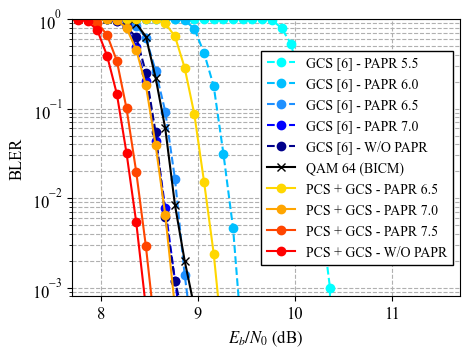

In [16]:
# import os
import matplotlib.font_manager as fm

local_fonts_path = os.path.expanduser('~/.local/share/fonts')
fm.fontManager.addfont(os.path.join(local_fonts_path, 'times.ttf'))

plt.rcParams.update({
    "font.size": 12,
    "grid.linestyle": "--",
    "axes.grid": True
})

plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'stix'

plt.figure(figsize=(5.0,3.6))

plt.semilogy(snr_all[0,:], ber_all[0,:], marker='o',linestyle='--', label="GCS [6] - PAPR 5.5", color='cyan')
plt.semilogy(snr_all[0,:], ber_all[1,:], marker='o',linestyle='--', label="GCS [6] - PAPR 6.0", color='deepskyblue')
plt.semilogy(snr_all[0,:], ber_all[2,:], marker='o',linestyle='--', label="GCS [6] - PAPR 6.5", color='dodgerblue')
plt.semilogy(snr_all[0,:], ber_all[3,:], marker='o',linestyle='--', label="GCS [6] - PAPR 7.0", color='blue')
# plt.semilogy(snr_all[0,:], ber_all[2,:], marker='o',linestyle='--', label="GCS [6] - PAPR 6.5", color='dodgerblue')
# plt.semilogy(snr_all[0,:], ber_all[3,:], marker='o',linestyle='--', label="GCS [6] - PAPR 7.0", color='blue')
plt.semilogy(snr_all[0,:], ber_all[4,:], marker='o',linestyle='--', label="GCS [6] - W/O PAPR", color='darkblue')
plt.semilogy(snr_all[0,:], ber_all[5,:], marker='x', label="QAM 64 (BICM)",color = 'black')
# plt.semilogy(snr_spiral[0,:], ber_spiral[0,:], marker='v', label="Spiral [23] (BICM)",color = 'black')
plt.semilogy(pcs_snr[1,:], pcs_bler[1,:], marker='o', label="PCS + GCS - PAPR 6.5", color='gold')
plt.semilogy(pcs_snr[2,:], pcs_bler[2,:], marker='o', label="PCS + GCS - PAPR 7.0", color='orange')
plt.semilogy(pcs_snr[3,:], pcs_bler[3,:], marker='o', label="PCS + GCS - PAPR 7.5", color='orangered')
plt.semilogy(pcs_snr[0,:], pcs_bler[0,:], marker='o', label="PCS + GCS - W/O PAPR", color='red')

plt.xlabel("$E_b/N_0$ (dB)")
plt.ylabel("BLER")
plt.ylim(8e-4, 1)
plt.xlim(7.7, 11.7)
# plt.title("BLER @ 120GHz PN , Blocklength 16200 DVB-S2X LDPC, SE = 3.6 bits/symbol ")
plt.grid(True, which="both")
plt.legend(loc = 'center right',
           framealpha=1,
           edgecolor=(0, 0, 0, 0),
           frameon=True,
           fancybox=False,
           ncol=1,
           fontsize=10)

plt.savefig('bler_papr_gcs_pcs_120Ghz.pdf',format="pdf",bbox_inches="tight",pad_inches=0.05)
plt.show()

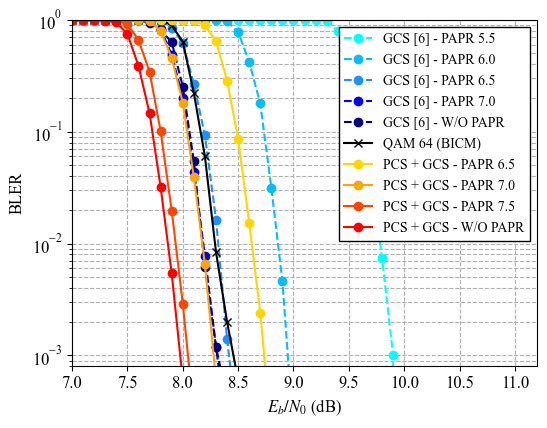

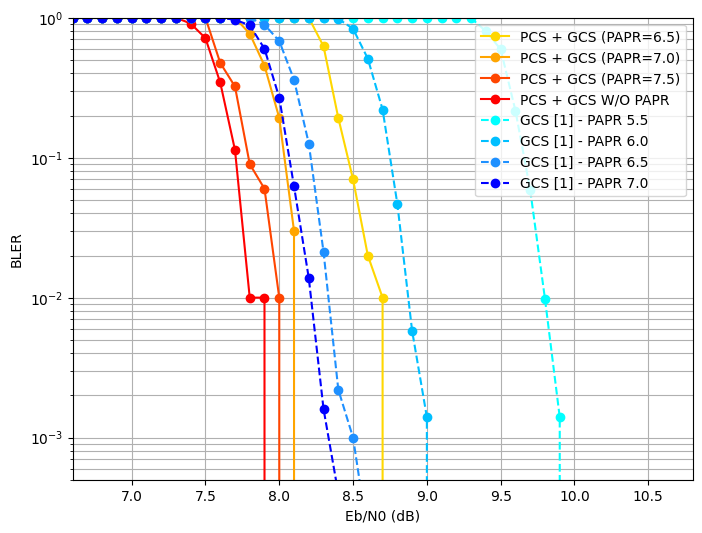

In [5]:
class PAS_scheme(Model):

    def __init__(self, batch_size, num_bp_iter, const_symbol_points, p_basic, probabilities, num_bits_per_symbol, use_upsampling_filtering_pn, use_neural_demapper, pn_freq, condition):
        super().__init__()

        self.batch_size = 1
        self.num_bits_per_symbol = num_bits_per_symbol
        self.N = 2**num_bits_per_symbol
        self.parity_k = 2 # Two bits represent parity bits, other four represent information

        r = 2/3   # m = 6 so (m-2)/m rate code is required here

        n_ldpc = 16200
        self.k_ldpc = int(n_ldpc*r)
        self.n_out = int(self.k_ldpc/(self.num_bits_per_symbol - self.parity_k))

        self.binary_source = BinarySource()

        parity_matrix = generate_ldpc_H_matrix(n_ldpc=n_ldpc,rate=r,q=15,file_path="ldpccode_short_2_3.txt")
        self.H_sparse = csr_matrix(parity_matrix[:, :self.k_ldpc])

        # p_basic = np.array([0.00622466, 0.01608852, 0.03347011, 0.02951173, 0.01565116, 0.03419713,
        #  0.07408216, 0.06683832, 0.03084535, 0.06940064, 0.14336276, 0.12366232,
        #  0.02854129, 0.06747344, 0.13703237, 0.12361801])

        [p_quant,self.k_input,self.n_i] = initialize(p_basic,self.n_out)

        # probabilities = np.tile(p_basic,(1,(2**self.parity_k)))/(2**self.parity_k)
        power = np.sum(probabilities * np.abs(const_symbol_points)**2)
        self.normalized_points = const_symbol_points / np.sqrt(power)

        self.channel = AWGN()
        constellation = Constellation("custom", num_bits_per_symbol=num_bits_per_symbol, points = self.normalized_points)
        self.mapper = Mapper(constellation=constellation)

        if pn_freq == '220':
            fc = 220e9
            pn_var = 0.0108
        elif pn_freq == '120':
            fc = 120e9
            pn_var = 0.0032

        self.use_neural_demapper = use_neural_demapper
        if not(use_neural_demapper):
            # self.demapper = Demapper("app", constellation=constellation) # APP demapper
            self.demapper = Demapper_optimized("app", constellation=constellation, pn_var=pn_var, condition=condition) # APP demapper
        else:
            # self.demapper1 = Demapper("app", constellation=constellation) # APP demapper
            # learned_pn_points = np.load(f"../const_shaping_symbol/results_32point_pn_220GHz/32point_const_points.npy")
            demodulator_weights = np.load("../const_shaping_symbol/results_32point_pn_220GHz/32point_const_demodulator_weights.npz")
            self.demapper = Demodulator_bitwise(2**num_bits_per_symbol, 10.0)
            # Dummy forward pass to trigger build
            dummy_x = tf.zeros((1, 5), dtype=tf.float32)
            _ = self.demapper(dummy_x)
            self.demapper.set_weights([
                demodulator_weights["weight_0"],
                demodulator_weights["weight_1"],
                demodulator_weights["weight_2"],
                demodulator_weights["weight_3"],
                demodulator_weights["weight_4"],
                demodulator_weights["weight_5"]
            ])

        num_bp_iter = 50
        llr_max_value = 120

        self.decoder = LDPCBPDecoder(parity_matrix, # connect encoder (for shared code parameters)
                                cn_update="boxplus-phi", # use the exact boxplus function
                                num_iter=num_bp_iter,
                                llr_max=llr_max_value,
                               hard_out=True)

        bit_labels = np.array([[int(b) for b in format(i, f'0{num_bits_per_symbol}b')] for i in range(self.N)])
        p_b1 = np.reshape(np.matmul(probabilities,bit_labels),(-1))
        self.prior = np.log(p_b1 / (1.0 - p_b1))

        self.bit_positions = np.arange((self.num_bits_per_symbol-self.parity_k)-1, -1, -1)


        self.mask = np.ones(self.num_bits_per_symbol, bool)
        self.mask[2:4] = False  # exclude parity positions

        self.use_upsampling_filtering_pn  = use_upsampling_filtering_pn

        if use_upsampling_filtering_pn:
            self.upsampler = sn.phy.signal.Upsampling(samples_per_symbol=4)
            self.tx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                             samples_per_symbol=4,
                                                             span_in_symbols=32)
            self.rx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                             samples_per_symbol=4,
                                                             span_in_symbols=32)

            num_ptrs_blocks = 32
            symbols_per_ptrs_block = 4
            block_size_ptrs = self.n_out+ 4*32
            bandwidth = 960e3*4096
            # fc = 220e9
            samples = 4*(block_size_ptrs+32)

            self.downsampler = sn.phy.signal.Downsampling(samples_per_symbol=4,
                                                          offset = self.rx_filter.length - 1,
                                                     num_symbols=tf.cast(block_size_ptrs, tf.int32))

            path_to_mat = "../PreloadedMats/ptrs_CAZAC_4_32.mat"

            self.ptrs_adder = PTRS_Adder(path_to_mat, num_ptrs_blocks, symbols_per_ptrs_block, block_size_ptrs, batch_size)
            self.pn_compensate = PN_Compensation(self.ptrs_adder.ptrs_indices, self.ptrs_adder.data_indices, block_size_ptrs\
                                                 , self.ptrs_adder.pilots,batch_size, num_ptrs_blocks, symbols_per_ptrs_block)
            self.pn_tx = PhaseNoise(model_type='13', bandwidth=bandwidth, fc=fc, n_samples=samples)
            self.pn_rx = PhaseNoise(model_type='11', bandwidth=bandwidth, fc=fc, n_samples=samples)


    # No Graph execution possible due to sequential CCDM Encode and Decode
    # Due to this no attempt was made to use tensorflow implementation
    def __call__(self, batch_size, ebno_db):
        no = ebnodb2no(ebno_db,
                       num_bits_per_symbol=3.6,
                       coderate=1)

        b_stream = np.array(self.binary_source([self.k_input]),np.int64)
        code_symbols = np.array(ccdm.encode(b_stream, self.n_out, self.n_i))
        reverse_map = (((code_symbols[:, None]-1) & (1 << np.arange(self.num_bits_per_symbol-self.parity_k)[::-1])) > 0).astype(int)
        enc_input = np.reshape(reverse_map,((self.num_bits_per_symbol-self.parity_k)*self.n_out))
        parity_bits = self.H_sparse.dot(enc_input) % 2  # mod 2 because XOR over GF(2)
        parity_bits = np.mod(np.cumsum(parity_bits) , 2)
        parity_reshaped = np.reshape(parity_bits,(-1,self.parity_k))
        # print('parity_reshaped.shape :', parity_reshaped.shape)
        # print('reverse_map.shape :', reverse_map.shape)
        # mapper_input_matrix = np.concatenate((parity_reshaped,reverse_map),axis=1)
        mapper_input_matrix = np.concatenate(
            (reverse_map[:, :2], parity_reshaped, reverse_map[:, -2:]),
            axis=1
        )
        mapper_input = np.reshape(mapper_input_matrix,(self.num_bits_per_symbol*self.n_out))
        x = self.mapper(mapper_input)

        #########################
        if self.use_upsampling_filtering_pn:
            ptrs_x_mod = self.ptrs_adder(tf.expand_dims(x,axis=0))
            x_up = self.upsampler(ptrs_x_mod)
            x_tx_filt = self.tx_filter(x_up)
            pn_out, _, _ = self.pn_tx(x_tx_filt)
            y_channel = self.channel(pn_out, no)
            y_channel_pn, _, _ = self.pn_rx(y_channel)
            y_rx_filt = self.rx_filter(y_channel_pn)
            y = self.downsampler(y_rx_filt)
            # print('y.shape: ',y.shape)
            _, y_data_vec = self.pn_compensate(y)
        else:
            y_data_vec = self.channel(x, no)
        #########################
        # # mean_squared = tf.reduce_mean(tf.abs(x) ** 2)
        # # print('meansquare',mean_squared.numpy())

        if self.use_neural_demapper:
            llr_ch = self.demapper(y_data_vec)
            # llr_ch1 = self.demapper1(y_data_vec, no, self.prior)
            # print('llr_ch.shape neural:',llr_ch.shape)
            # print('llr_ch.shape map:',llr_ch1.shape)
            # # First two symbols from neural demapper
            # llr_neural_two_symbols = llr_ch[0, 0:4, :]  # shape (2, 5)

            # # First two symbols from map-based demapper
            # llr_map_flat = llr_ch1[0, 0:20]             # shape (10,)
            # llr_map_two_symbols = np.reshape(llr_map_flat, (4, 5))

            # print("LLRs (neural) for first 2 symbols:")
            # print(llr_neural_two_symbols)

            # print("LLRs (map) for first 2 symbols:")
            # print(llr_map_two_symbols)

        else:
            # llr_ch = self.demapper(y_data_vec, no, self.prior)
            llr_ch = self.demapper(y_data_vec, no, self.normalized_points, self.prior)
            # print('llr_ch.shape 2:',llr_ch.shape)
        llr_reshaped = np.reshape(llr_ch,(-1,self.num_bits_per_symbol))

        # llr_parity_comp = np.reshape(llr_reshaped[:,:self.parity_k],(-1))
        # llr_amplitude_comp = np.reshape(llr_reshaped[:,self.parity_k:],(-1))
        llr_parity_comp    = np.reshape(llr_reshaped[:, ~self.mask], (-1,))
        llr_amplitude_comp = np.reshape(llr_reshaped[:, self.mask], (-1,))

        codeword_llr = np.hstack((llr_amplitude_comp, llr_parity_comp))
        decoded_bits = tf.cast(self.decoder(codeword_llr),tf.int64).numpy()
        info_bits_reshaped = np.reshape(decoded_bits[:self.k_ldpc],(-1,self.num_bits_per_symbol-self.parity_k))
        # Use bitwise left shift to compute powers of two
        shifted_bits = info_bits_reshaped << self.bit_positions
        # Compute the integer representation using bitwise operations
        code_symbols_retrieved = np.sum(shifted_bits, axis=-1)+1
        # tf.print('ccdm input: ', code_symbols_retrieved.shape)
        decoded_bits_ccdmdec = ccdm.decode(code_symbols_retrieved, self.n_i, self.k_input)
        missing = self.k_input - len(decoded_bits_ccdmdec)
        if missing > 0:
            decoded_bits_ccdmdec.extend([0] * missing)
        # tf.print('ccdm :',np.array(decoded_bits_ccdmdec).shape)
        # tf.print('b_stream :',b_stream.shape)

        return b_stream, decoded_bits_ccdmdec


In [24]:
data = np.load("snr_13_papr_No PAPR_120.npz")

In [12]:
N = 64
num_bits_per_symbol = int(np.log2(N))
batch_size = 40
num_bp_iter = 50
use_dvb = True
use_upsampling_filtering_pn = True
use_neural_demapper = False
pn_freq = '120'
condition = 'lowpn' # awgn highsnr

ber_plot_pas = PlotBER("ber_plot_pas")

##################### CHeck these
points = np.array(data["constellation_points"])

p0 = 0.8544
##################################

labels = np.arange(N)
bin_labels = ((labels[:, None] & (1 << np.arange(num_bits_per_symbol - 1, -1, -1))) > 0).astype(int)
first_bits = bin_labels[:, 0]  # First (MSB) bit
probabilities = tf.where(first_bits == 0, p0 / (2 ** (num_bits_per_symbol - 1)), (1 - p0) / (2 ** (num_bits_per_symbol - 1)))

p_basic_mask = (bin_labels[:, 2] == 0) & (bin_labels[:, 3] == 0)
prob_basic_set = probabilities[p_basic_mask]*4





In [14]:
RESULTS_DIR = "results_64_pn_120Hz_lowpn"
exp_name = f"snr_{13}_papr_{'No PAPR'}"
data = np.load(f"{RESULTS_DIR}/{exp_name}.npz")
points = data["constellation_points"]
probabilities = data["constellation_probabilities"]

EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      6.6 | 4.9893e-01 | 1.0000e+00 |       48117 |       96440 |           10 |          10 |         9.2 |reached target block errors
     6.76 | 5.0033e-01 | 1.0000e+00 |       48252 |       96440 |           10 |          10 |         9.1 |reached target block errors
     6.92 | 4.9929e-01 | 1.0000e+00 |       48152 |       96440 |           10 |          10 |         9.0 |reached target block errors
     7.08 | 4.9833e-01 | 1.0000e+00 |       48059 |       96440 |           10 |          10 |         9.0 |reached target block errors
     7.24 | 5.0044e-01 | 1.0000e+00 |       48262 |       96440 |           10 |          10 |         9.2 |reached target block errors
      7.4 | 4.9831e-01 | 1.0000e+00 |       48057 |       96440 |

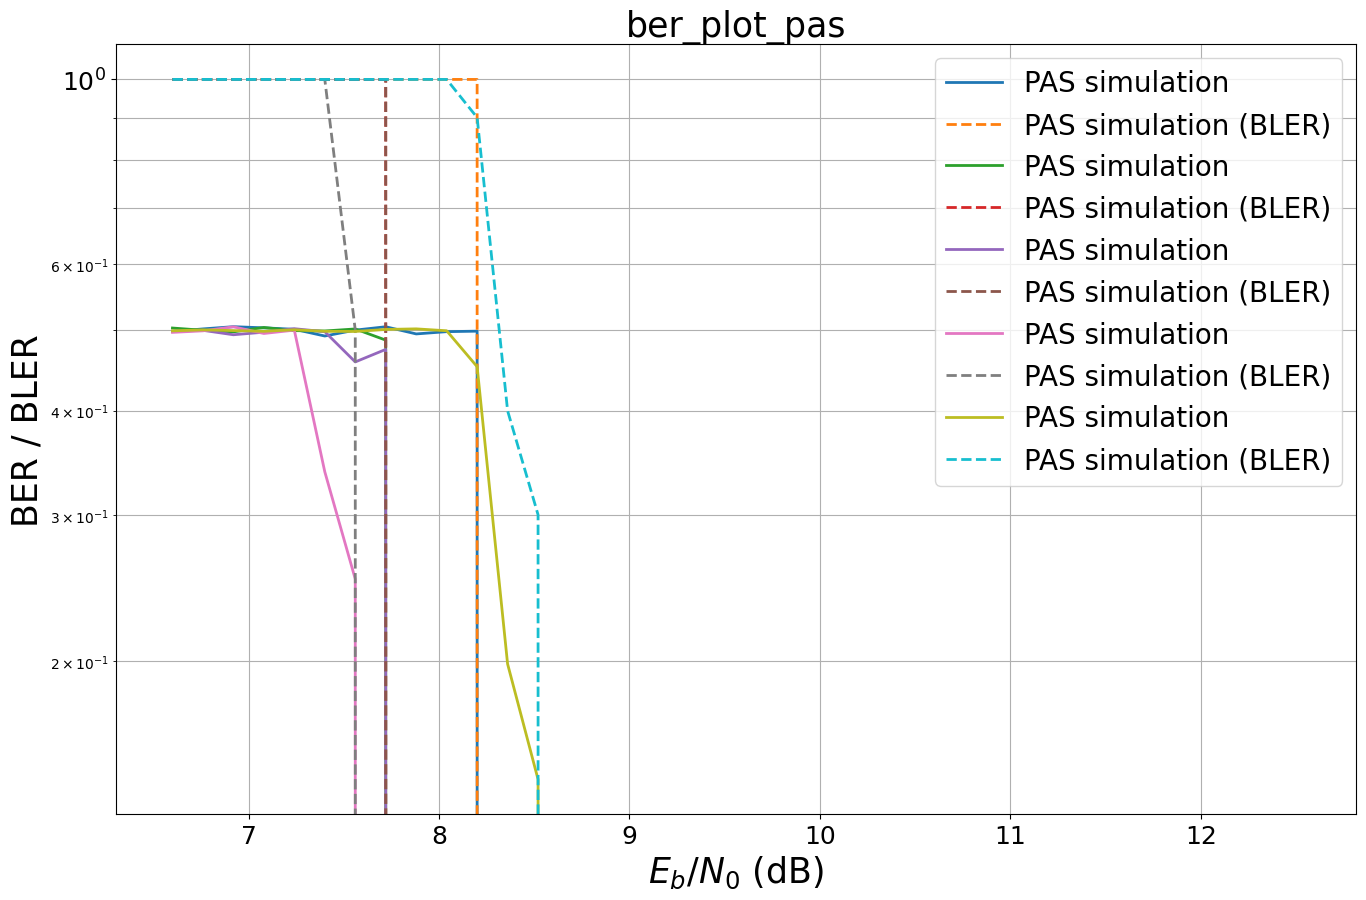

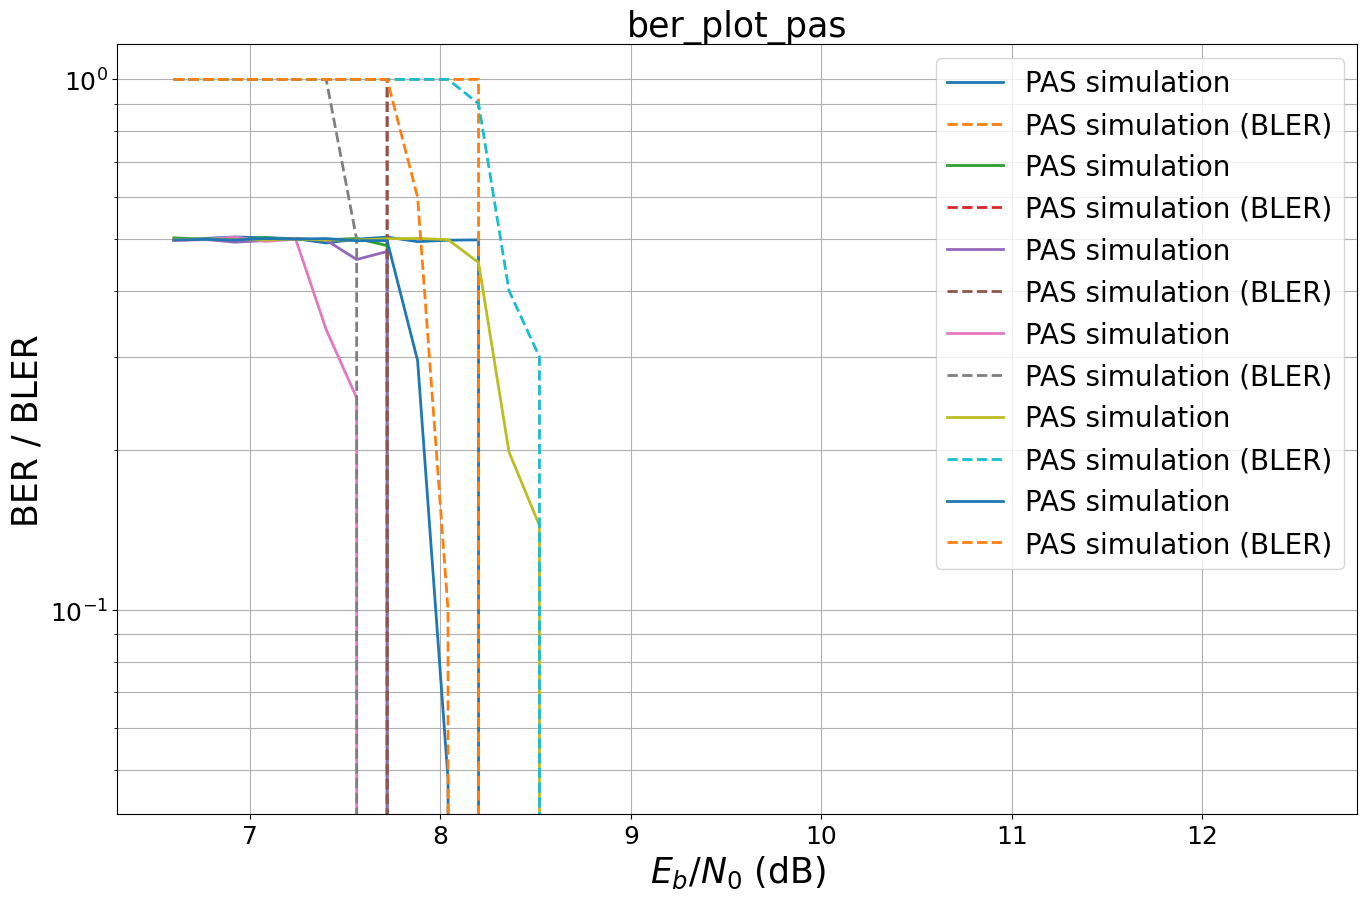

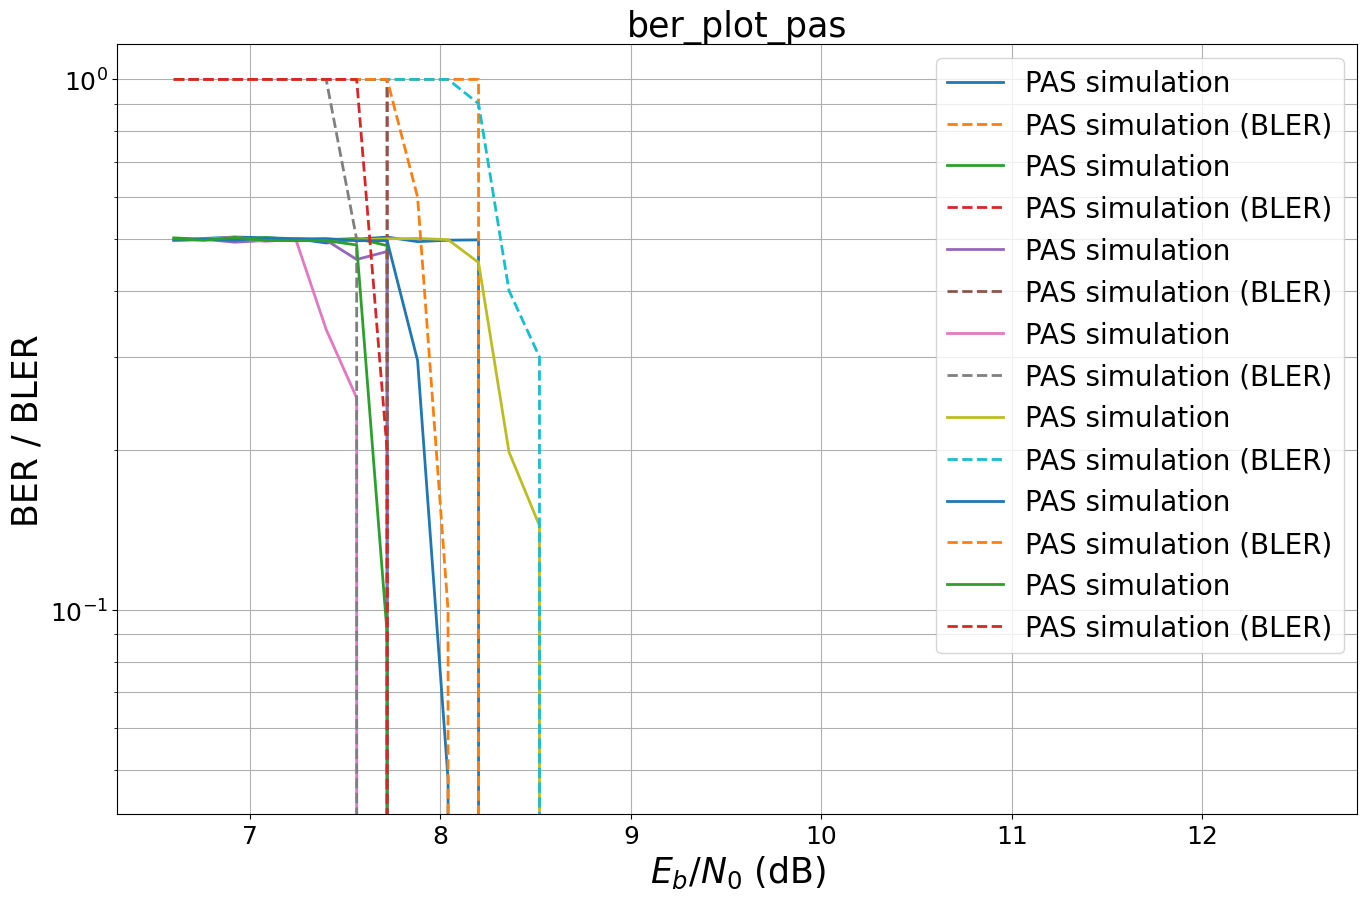

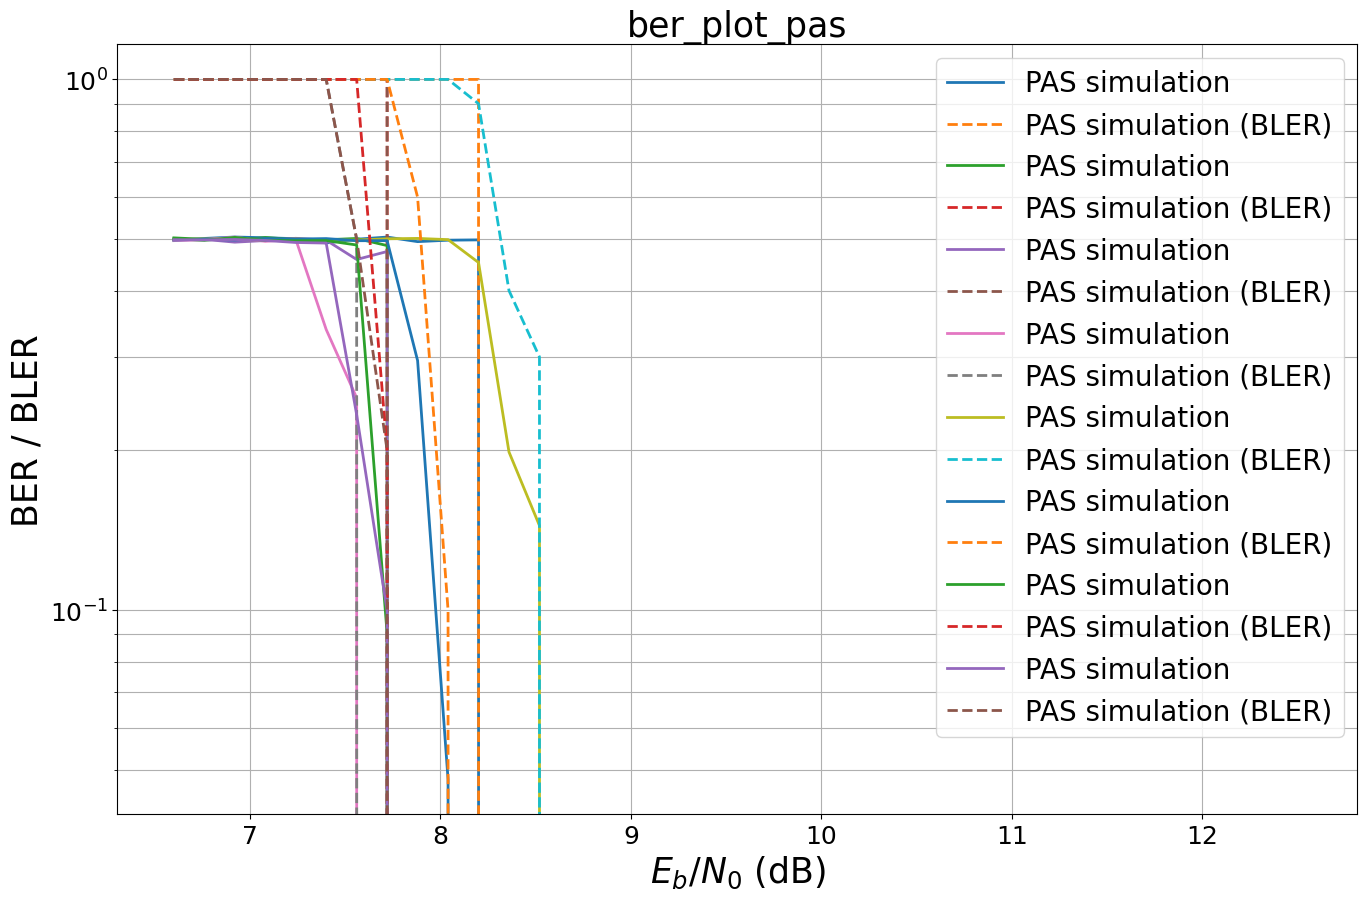

In [15]:
RESULTS_DIR = "results_64_pn_120Hz_lowpn"

snr_list = [13]
papr_list = [6.5, 7.0, 7.5, 'No PAPR']

for snr_db in snr_list:
    for papr_db in papr_list:
        exp_name = f"snr_{snr_db}_papr_{papr_db}"
        plotname = f"papr_{papr_db}"
        data = np.load(f"{RESULTS_DIR}/{exp_name}.npz")
        points = data["constellation_points"]
        probabilities = data["constellation_probabilities"]

        pas_model = PAS_scheme(1, 50, points, prob_basic_set, probabilities, num_bits_per_symbol, use_upsampling_filtering_pn, use_neural_demapper, pn_freq, condition)

        ber_plot_pas.simulate(pas_model, # the function have defined previously
                                  ebno_dbs= np.arange(6.6, 12.64, 0.16), # sim SNR range
                                  legend='PAS simulation',
                                  add_bler = True,
                                  add_ber = True,
                                  max_mc_iter=10,#1000
                                  num_target_block_errors=10,
                                  batch_size=1,
                                  soft_estimates=False,
                                  early_stop=True,
                                  show_fig=True,
                                  forward_keyboard_interrupt=False)

